# Step 3 · 3주차 평가와 임계값 설계

Colab의 **런타임 → 런타임 유형 변경 → GPU**를 선택하고 위에서부터 순서대로 실행한다.
0번 준비 셀 하나에서 이전 주차의 모델·데이터·분할 기록을 연결한다. 이후 코드 셀 10개는
3주차 강의자료의 순서를 따른다. 출력 파일은 Drive의 `딥러닝/step3_week3/results`에 저장한다.

검증셋에서 클래스별 임계값을 선택하고 테스트셋에는 고정 적용한다.
강의자료의 임계값 후보와 동점 처리 방식을 사용한다. 낮은 임계값을 비교할 수 있도록
추론에는 `conf=0.001`을 명시하였다. 반복하는 ON/OFF 계산에서는 같은 영상의 예측 점수를 재사용한다.

2주차에 제공 라벨로 학습한 실행의 `best.pt`와 `split_manifest.csv`를 사용한다.
직접 주석 ZIP은 이번 평가에서 추가로 덮어쓰지 않는다.

## 0. 이전 주차 준비 요약 · 한 셀

설치, Drive 연결, 2주차 분할 복원, 영상별 정답 클래스 목록 생성을 수행한다.
학습 실행이 `step3` 이외의 이름으로 저장되었다면 `BEST_PT`만 실제 경로로 수정한다.
원본 ZIP에서 기존 분할에 해당하는 검증·테스트 영상과 제공 라벨만 복원한다.

이미지 읽기 오류가 있으면 OpenCV로 다시 읽어 PNG로 저장한다. 두 라이브러리 모두 읽지 못한 영상은
모델 평가 전에 제외하고 `image_read_issues.csv`에 원본 파일명과 사유를 기록한다.
`evaluation_manifest.csv`에는 실제 평가 영상을 기록한다. 제외 수와 최종 검증·테스트 영상 수를
보고서의 데이터 점검 항목에 함께 기재한다. 수정본은 0번부터 순서대로 다시 실행한다.


In [1]:
%pip install -q ultralytics

import csv
import hashlib
import json
import random
from collections import Counter
from pathlib import Path
from zipfile import ZipFile

import cv2
import numpy as np
import torch
import ultralytics
import yaml
from google.colab import drive
from PIL import Image, UnidentifiedImageError

drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/딥러닝")
WEEK2_DIR = DRIVE_DIR / "step3_week2"
ZIP_PATH = DRIVE_DIR / "사용한 데이터.zip"
MANIFEST_PATH = WEEK2_DIR / "split_manifest.csv"
BEST_PT = WEEK2_DIR / "runs" / "step3" / "weights" / "best.pt"
BASE_DIR = DRIVE_DIR / "step3_week3"
RESULT_DIR = BASE_DIR / "results"
DATA_ROOT = Path("/content/step3_week3/dataset_split")
DATA_YAML = DATA_ROOT / "data.yaml"
CLASS_NAMES = {0: "crack", 1: "efflorescence", 2: "spall_detach"}
SEED = 42
PRED_CONF = 0.001
DEVICE = 0 if torch.cuda.is_available() else "cpu"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

for path in (ZIP_PATH, MANIFEST_PATH, BEST_PT):
    if not path.is_file():
        raise FileNotFoundError(f"준비 파일 경로를 확인하십시오: {path}")

with MANIFEST_PATH.open(encoding="utf-8-sig", newline="") as file:
    manifest = list(csv.DictReader(file))
if not manifest:
    raise ValueError("분할 기록이 비어 있습니다.")

# 2주차에 저장한 원본 ID 배정을 그대로 사용한다.
split_ids = {
    split: {row["origin_id"] for row in manifest if row["split"] == split}
    for split in ("train", "val", "test")
}
overlaps = {
    "train/val": len(split_ids["train"] & split_ids["val"]),
    "train/test": len(split_ids["train"] & split_ids["test"]),
    "val/test": len(split_ids["val"] & split_ids["test"]),
}
assert not any(overlaps.values()), f"원본 ID 중복: {overlaps}"
eval_rows = [row for row in manifest if row["split"] in ("val", "test")]
if not all(any(row["split"] == split for row in eval_rows) for split in ("val", "test")):
    raise ValueError("검증셋과 테스트셋의 분할 기록이 모두 필요합니다.")
if len({row["output_image"] for row in eval_rows}) != len(eval_rows):
    raise ValueError("분할 기록에 중복된 출력 영상 경로가 있습니다.")

# YAML에는 평가 전용 복원 폴더를 지정한다. 실제 파일 목록은 manifest에서 가져온다.
for split in ("train", "val", "test"):
    (DATA_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATA_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

val_imgs, val_gts, test_imgs, test_gts = [], [], [], []
label_paths = {}
image_read_issues = []
evaluation_manifest = []
with ZipFile(ZIP_PATH) as archive:
    members = set(archive.namelist())
    marker = "images/" + eval_rows[0]["source_key"] + ".jpg"
    roots = [name[:-len(marker)] for name in members if name.endswith(marker)]
    if len(roots) != 1:
        raise ValueError("ZIP 안의 images 폴더와 분할 기록의 파일명을 확인하십시오.")
    source_root = roots[0]
    for row in eval_rows:
        image_member = source_root + "images/" + row["source_key"] + ".jpg"
        label_member = source_root + "labels/" + row["source_key"] + ".txt"
        if image_member not in members or label_member not in members:
            raise FileNotFoundError(f"원본 영상/라벨 쌍이 없습니다: {row['source_key']}")
        image_path = DATA_ROOT / row["output_image"]
        relative_image = Path(row["output_image"]).relative_to("images")
        if relative_image.parts[0] != row["split"] or ".." in relative_image.parts:
            raise ValueError(f"분할 경로가 일치하지 않습니다: {row['output_image']}")
        label_path = DATA_ROOT / "labels" / relative_image.with_suffix(".txt")
        image_path.parent.mkdir(parents=True, exist_ok=True)
        label_path.parent.mkdir(parents=True, exist_ok=True)
        image_bytes = archive.read(image_member)
        image_path.write_bytes(image_bytes)
        read_status = "original"
        try:
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.load()
        except (UnidentifiedImageError, OSError, ValueError) as error:
            # 같은 바이트를 OpenCV로 읽을 수 있으면 좌표계를 보존해 PNG로 저장한다.
            # IMREAD_UNCHANGED는 EXIF에 따른 자동 회전을 적용하지 않는다.
            try:
                decoded = cv2.imdecode(np.frombuffer(image_bytes, np.uint8), cv2.IMREAD_UNCHANGED)
            except cv2.error:
                decoded = None
            issue = {
                "split": row["split"], "source_key": row["source_key"],
                "bytes": len(image_bytes), "header_hex": image_bytes[:24].hex(),
                "pillow_error": str(error), "action": "excluded_unreadable", "evaluation_image": "",
            }
            if decoded is None or decoded.size == 0:
                image_read_issues.append(issue)
                image_path.unlink(missing_ok=True)
                print("읽기 실패로 평가 제외:", row["source_key"])
                continue
            converted_path = image_path.with_suffix(".png")
            if not cv2.imwrite(str(converted_path), decoded):
                raise OSError(f"PNG 저장 실패: {converted_path}")
            with Image.open(converted_path) as image:
                image.load()
                if image.size != (decoded.shape[1], decoded.shape[0]):
                    raise ValueError(f"변환 후 영상 크기가 달라졌습니다: {converted_path}")
            image_path.unlink(missing_ok=True)
            image_path = converted_path
            read_status = "opencv_reencoded_png"
            issue.update(action=read_status, evaluation_image=image_path.relative_to(DATA_ROOT).as_posix())
            image_read_issues.append(issue)
            print("OpenCV로 읽은 뒤 PNG 저장:", row["source_key"])
        label_text = archive.read(label_member).decode("utf-8-sig")
        label_path.write_text(label_text, encoding="utf-8")
        gt_classes = set()
        for line in label_text.splitlines():
            values = line.split()
            if not values:
                continue
            cid = int(values[0])
            coords = [float(v) for v in values[1:]]
            if (cid not in CLASS_NAMES or len(coords) < 6 or len(coords) % 2
                    or not all(0 <= value <= 1 for value in coords)):
                raise ValueError(f"폴리곤 라벨 형식을 확인하십시오: {label_path}")
            gt_classes.add(cid)
        evaluation_manifest.append({
            **row, "evaluation_image": image_path.relative_to(DATA_ROOT).as_posix(),
            "read_status": read_status,
        })
        label_paths[str(image_path)] = label_path
        if row["split"] == "val":
            val_imgs.append(image_path)
            val_gts.append(gt_classes)
        else:
            test_imgs.append(image_path)
            test_gts.append(gt_classes)

# 읽기 문제와 실제 평가 대상을 먼저 기록한다. 모든 평가는 아래 동일한 목록을 사용한다.
with (RESULT_DIR / "image_read_issues.csv").open("w", encoding="utf-8-sig", newline="") as file:
    fields = ["split", "source_key", "bytes", "header_hex", "pillow_error", "action", "evaluation_image"]
    writer = csv.DictWriter(file, fieldnames=fields)
    writer.writeheader()
    writer.writerows(image_read_issues)
with (RESULT_DIR / "evaluation_manifest.csv").open("w", encoding="utf-8-sig", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=[*manifest[0], "evaluation_image", "read_status"])
    writer.writeheader()
    writer.writerows(evaluation_manifest)
if not val_imgs or not test_imgs:
    raise ValueError("읽을 수 있는 검증/테스트 영상이 부족합니다. image_read_issues.csv를 확인하십시오.")

# 디렉터리에 남아 있는 이전 실행 파일이 평가 목록에 섞이지 않게 목록을 명시한다.
for split, paths in (("val", val_imgs), ("test", test_imgs)):
    (DATA_ROOT / f"{split}.txt").write_text(
        "\n".join(str(path) for path in paths) + "\n", encoding="utf-8"
    )
data_yaml = {
    "path": str(DATA_ROOT), "train": "images/train",
    "val": "val.txt", "test": "test.txt", "names": CLASS_NAMES,
}
yaml_text = yaml.safe_dump(data_yaml, allow_unicode=True, sort_keys=False)
DATA_YAML.write_text(yaml_text, encoding="utf-8")
(RESULT_DIR / "data.yaml").write_text(yaml_text, encoding="utf-8")
(RESULT_DIR / "split_manifest.csv").write_bytes(MANIFEST_PATH.read_bytes())

environment = {
    "torch": str(torch.__version__), "ultralytics": ultralytics.__version__,
    "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU",
    "seed": SEED, "imgsz": 960, "predict_conf": PRED_CONF,
    "best_pt": str(BEST_PT),
    "best_pt_sha256": hashlib.sha256(BEST_PT.read_bytes()).hexdigest(),
    "manifest_sha256": hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest(),
    "val_images": len(val_imgs), "test_images": len(test_imgs),
    "evaluation_manifest_sha256": hashlib.sha256(
        (RESULT_DIR / "evaluation_manifest.csv").read_bytes()
    ).hexdigest(),
    "excluded_unreadable_images": sum(r["action"] == "excluded_unreadable" for r in image_read_issues),
    "reencoded_images": sum(r["action"] == "opencv_reencoded_png" for r in image_read_issues),
    "original_id_overlap": overlaps, "evaluation_labels": "provided labels from source ZIP",
}
(RESULT_DIR / "environment.json").write_text(
    json.dumps(environment, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("GPU:", environment["gpu"])
print("best.pt:", BEST_PT)
print("split 간 원본 ID 중복:", overlaps)
for split, gts in (("val", val_gts), ("test", test_gts)):
    print(split, "영상 수:", len(gts), "| 클래스별 ON 영상 수:",
          {name: sum(cid in gt for gt in gts) for cid, name in CLASS_NAMES.items()})
print("결과 저장 폴더:", RESULT_DIR)
print("읽기 실패 제외 영상 수:", environment["excluded_unreadable_images"])
print("PNG 재저장 영상 수:", environment["reencoded_images"])
print("읽기 문제 기록:", RESULT_DIR / "image_read_issues.csv")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
requirements: Ultralytics requirement ['pi-heif'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 316ms
Prepared 1 package in 63ms
Installed 1 package in 2ms
 + pi-heif==1.4.0

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

읽기 실패로 평가 제외: train/URT020_2021_04_03_001_2914
GPU: Tesla T4
best.pt: /content/drive/MyDrive/딥러닝/step3_week2/runs/step3/weights/best.pt
split 간 원본 ID 중복: {'train/val': 0, 'train/test': 0, 'val/test': 0}
val 영상 수: 21 | 클래스별 ON 영상 수: {'crack': 7, 'efflorescence': 3, 'spall_detach': 11}
test 영상 수: 20 | 클래스별 ON 영상 수: {'crack': 2

## 1. 세그멘테이션 성능 측정

강의자료의 `BASE_DIR`, `DATA_YAML`, `BEST_PT`는 준비 셀에서 Colab 경로로 설정하였다.
파일 존재 여부를 확인한다.

In [2]:
from pathlib import Path
from ultralytics import YOLO

if not DATA_YAML.exists():
    raise FileNotFoundError(f"data.yaml을 찾을 수 없습니다: {DATA_YAML}")
if not BEST_PT.exists():
    raise FileNotFoundError(f"best.pt를 찾을 수 없습니다: {BEST_PT}")

print("DATA_YAML:", DATA_YAML)
print("BEST_PT:", BEST_PT)

DATA_YAML: /content/step3_week3/dataset_split/data.yaml
BEST_PT: /content/drive/MyDrive/딥러닝/step3_week2/runs/step3/weights/best.pt


## 2. 세그멘테이션 성능 측정 코드(2)

테스트셋에서 전체 및 클래스별 mask mAP50, mAP50-95를 산출한다.
클래스별 지표는 해당 클래스의 AP를 표시한다. 정답이 없는 클래스는 `NaN`으로 표시한다.

In [3]:
import pandas as pd

model = YOLO(str(BEST_PT))
if model.task != "segment" or model.names != CLASS_NAMES:
    raise ValueError(f"세그멘테이션 모델과 클래스 순서를 확인하십시오: {model.names}")

results = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=960,
    plots=True,
    batch=4,
    device=DEVICE,
    project=str(RESULT_DIR),
    name="segmentation_test",
    exist_ok=True,
)

print("mask mAP50   :", round(results.seg.map50, 4))
print("mask mAP50-95:", round(results.seg.map, 4))
print("box mAP50    :", round(results.box.map50, 4))

class_names = ["crack", "efflorescence", "spall_detach"]
evaluated = {int(cid): i for i, cid in enumerate(results.seg.ap_class_index)}
seg_rows = []
for cid, name in enumerate(class_names):
    index = evaluated.get(cid)
    ap50 = float(results.seg.ap50[index]) if index is not None else float("nan")
    ap = float(results.seg.ap[index]) if index is not None else float("nan")
    seg_rows.append([name, ap50, ap, sum(cid in gt for gt in test_gts)])
    print(name, "mask AP50:", round(ap50, 4), "| mask AP50-95:", round(ap, 4))

seg_df = pd.DataFrame(seg_rows, columns=["class", "mask_AP50", "mask_AP50-95", "GT_ON_images"])
seg_df.to_csv(RESULT_DIR / "test_segmentation_by_class.csv", index=False, encoding="utf-8-sig")
pd.DataFrame([{
    "mask_mAP50": float(results.seg.map50),
    "mask_mAP50-95": float(results.seg.map),
    "box_mAP50": float(results.box.map50),
}]).to_csv(RESULT_DIR / "test_segmentation_overall.csv", index=False, encoding="utf-8-sig")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-seg summary (fused): 85 layers, 11,780,761 parameters, 0 gradients, 39.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1940.1±943.1 MB/s, size: 242.5 KB)
val: Scanning /content/step3_week3/dataset_split/labels/test/test... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 1.8Kit/s 0.0s
val: New cache created: /content/step3_week3/dataset_split/labels/test/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.9it/s 1.7s
                   all         20         24      0.712      0.775      0.752      0.547      0.712      0.775      0.746      0.385
                 crack          2          2      0.653      0.958      0.828      0.712      0.653      0.958      0.828      0.381
         efflorescence         10         12      0.687      0.667      0.701     

## 3. ON/OFF 평가 구현

강의자료의 함수는 한 셀에서 완성해 실행할 수 있도록 구성하였다.
정답과 예측의 클래스 존재 여부로 TP·FP·FN·TN을 영상 단위로 계산한다.
낮은 confidence의 예측까지 얻고, 반복 평가에서 클래스와 점수만 재사용한다.

In [5]:
import numpy as np

prediction_cache = {}

def onoff(model, paths, gts, thr, cid_target):
    if len(paths) != len(gts):
        raise ValueError("영상 경로와 정답 목록의 개수가 다릅니다.")
    if thr < PRED_CONF:
        raise ValueError("탐색 임계값은 추론 conf 이상이어야 합니다.")
    tp = fp = fn = tn = 0

    for p, gt in zip(paths, gts):
        key = (id(model), str(p), PRED_CONF)
        if key not in prediction_cache:
            r = model.predict(
                str(p),
                imgsz=960,
                conf=PRED_CONF,
                device=DEVICE,
                verbose=False,
            )[0]
            conf = r.boxes.conf.cpu().numpy()
            cid = r.boxes.cls.cpu().numpy().astype(int)
            prediction_cache[key] = (conf, cid)
        conf, cid = prediction_cache[key]

        pred_on = bool(((cid == cid_target) & (conf >= thr)).any())
        gt_on = cid_target in gt
        if gt_on and pred_on:
            tp += 1
        elif not gt_on and pred_on:
            fp += 1
        elif gt_on and not pred_on:
            fn += 1
        else:
            tn += 1

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "precision": precision, "recall": recall, "f1": f1}

## 4. ON/OFF 평가 구현 코드(2)

강의자료의 확인 방법대로 검증셋에서 `thr=0.5`로 먼저 실행한다.
각 클래스의 TP+FP+FN+TN 합이 검증 영상 수와 같은지 확인한다.

In [6]:
class_names = ["crack", "efflorescence", "spall_detach"]
for cid, name in enumerate(class_names):
    r = onoff(model, val_imgs, val_gts, 0.5, cid)
    assert r["tp"] + r["fp"] + r["fn"] + r["tn"] == len(val_imgs)
    print(name, "| threshold=0.5 |", r)

crack | threshold=0.5 | {'tp': 2, 'fp': 0, 'fn': 5, 'tn': 14, 'precision': 1.0, 'recall': 0.2857142857142857, 'f1': 0.4444444444444445}
efflorescence | threshold=0.5 | {'tp': 2, 'fp': 0, 'fn': 1, 'tn': 18, 'precision': 1.0, 'recall': 0.6666666666666666, 'f1': 0.8}
spall_detach | threshold=0.5 | {'tp': 5, 'fp': 0, 'fn': 6, 'tn': 10, 'precision': 1.0, 'recall': 0.45454545454545453, 'f1': 0.625}


## 5. 임계값 탐색 — 검증셋에서만

강의자료의 후보 임계값을 사용한다. 이 셀을 다시 실행하면 선택 결과를 초기화한다.
검증셋에 정답 ON 영상이 없는 클래스의 F1은 임계값 선택 근거로 해석하기 어렵다.
준비 셀의 클래스별 ON 영상 수를 함께 기록한다.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

THRS = [0.001, 0.004, 0.01, 0.02, 0.06, 0.1, 0.2, 0.3]
class_names = ["crack", "efflorescence", "spall_detach"]
best = {}
all_scores = {}
threshold_rows = []

## 6. 임계값 탐색 — 검증셋에서만 코드(2)

클래스별 최고 F1을 찾고 동점이면 낮은 임계값을 선택한다.
`val_threshold_f1.png`, 탐색 결과 CSV, `selected_thresholds.json`을 저장한다.

crack | thr=0.001 | F1=0.824 | FP=3 | FN=0
crack | thr=0.004 | F1=0.923 | FP=0 | FN=1
crack | thr=0.010 | F1=0.833 | FP=0 | FN=2
crack | thr=0.020 | F1=0.833 | FP=0 | FN=2
crack | thr=0.060 | F1=0.833 | FP=0 | FN=2
crack | thr=0.100 | F1=0.833 | FP=0 | FN=2
crack | thr=0.200 | F1=0.727 | FP=0 | FN=3
crack | thr=0.300 | F1=0.600 | FP=0 | FN=4
>> crack 선택 임계값: 0.004 (F1=0.923)

efflorescence | thr=0.001 | F1=0.462 | FP=7 | FN=0
efflorescence | thr=0.004 | F1=0.600 | FP=4 | FN=0
efflorescence | thr=0.010 | F1=0.750 | FP=2 | FN=0
efflorescence | thr=0.020 | F1=0.750 | FP=2 | FN=0
efflorescence | thr=0.060 | F1=0.750 | FP=2 | FN=0
efflorescence | thr=0.100 | F1=0.857 | FP=1 | FN=0
efflorescence | thr=0.200 | F1=0.857 | FP=1 | FN=0
efflorescence | thr=0.300 | F1=0.857 | FP=1 | FN=0
>> efflorescence 선택 임계값: 0.1 (F1=0.857)

spall_detach | thr=0.001 | F1=0.846 | FP=4 | FN=0
spall_detach | thr=0.004 | F1=0.880 | FP=3 | FN=0
spall_detach | thr=0.010 | F1=0.762 | FP=2 | FN=3
spall_detach | thr=0.0

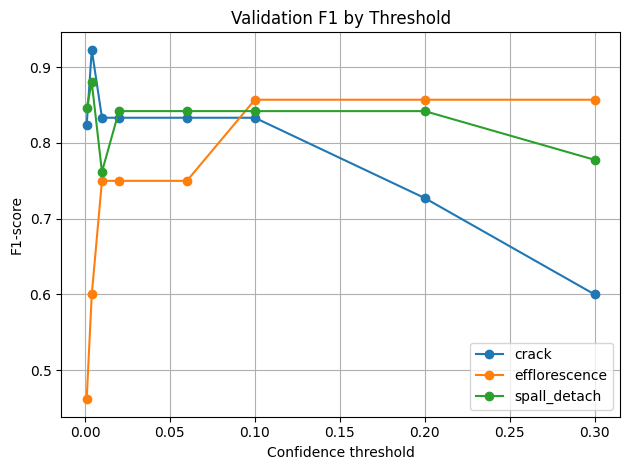

727

In [8]:
for cid, name in enumerate(class_names):
    scores = []
    for t in THRS:
        r = onoff(model, val_imgs, val_gts, t, cid)
        scores.append(r["f1"])
        threshold_rows.append({"class": name, "threshold": t, **r})
        print(f"{name} | thr={t:.3f} | F1={r['f1']:.3f} | FP={r['fp']} | FN={r['fn']}")

    all_scores[name] = scores
    max_f1 = max(scores)
    best_idx = next(i for i, score in enumerate(scores) if score == max_f1)
    best[name] = THRS[best_idx]
    print(f">> {name} 선택 임계값: {best[name]} (F1={max_f1:.3f})\n")

print("최종 임계값:", best)
fig, ax = plt.subplots()
for name in class_names:
    ax.plot(THRS, all_scores[name], marker="o", label=name)
ax.set_xlabel("Confidence threshold")
ax.set_ylabel("F1-score")
ax.set_title("Validation F1 by Threshold")
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig(RESULT_DIR / "val_threshold_f1.png", dpi=150)
plt.show()

pd.DataFrame(threshold_rows).to_csv(
    RESULT_DIR / "val_threshold_scores.csv", index=False, encoding="utf-8-sig"
)
threshold_config = {
    "selected_on": "val", "thresholds": best, "candidates": THRS,
    "selection_rule": "max validation image-level F1; lowest threshold on ties",
    "validation_f1": {name: max(all_scores[name]) for name in class_names},
    "predict_conf": PRED_CONF, "best_pt_sha256": environment["best_pt_sha256"],
    "manifest_sha256": environment["manifest_sha256"],
    "evaluation_manifest_sha256": environment["evaluation_manifest_sha256"],
}
(RESULT_DIR / "selected_thresholds.json").write_text(
    json.dumps(threshold_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

## 7. 테스트셋 고정 적용

검증셋에서 저장한 임계값을 읽어 테스트셋에 그대로 적용한다.
모델과 분할 기록이 임계값을 선택할 때와 같은지 확인한다.

In [9]:
import pandas as pd

threshold_config = json.loads((RESULT_DIR / "selected_thresholds.json").read_text(encoding="utf-8"))
assert threshold_config["selected_on"] == "val"
assert threshold_config["best_pt_sha256"] == environment["best_pt_sha256"]
assert threshold_config["manifest_sha256"] == environment["manifest_sha256"]
assert threshold_config["evaluation_manifest_sha256"] == environment["evaluation_manifest_sha256"]
best = threshold_config["thresholds"]
class_names = ["crack", "efflorescence", "spall_detach"]
rows = []
for cid, name in enumerate(class_names):
    r = onoff(model, test_imgs, test_gts, best[name], cid)
    assert r["tp"] + r["fp"] + r["fn"] + r["tn"] == len(test_imgs)
    rows.append([name, best[name], r["tp"], r["fp"], r["fn"], r["tn"],
                 r["precision"], r["recall"], r["f1"]])

## 8. 테스트셋 고정 적용 코드(2)

클래스별 TP·FP·FN·TN·Precision·Recall·F1과 macro F1을 출력하고 저장한다.

In [10]:
df = pd.DataFrame(rows, columns=[
    "class", "threshold", "TP", "FP", "FN", "TN", "precision", "recall", "f1"
])
macro_f1 = float(df["f1"].mean())
print(df.round(3).to_string(index=False))
print("macro F1:", round(macro_f1, 3))
df.to_csv(RESULT_DIR / "test_onoff_results.csv", index=False, encoding="utf-8-sig")
(RESULT_DIR / "test_macro_f1.json").write_text(
    json.dumps({"macro_f1": macro_f1}, indent=2), encoding="utf-8"
)

# 영상별 점수와 정답도 저장해 오류 사례와 집계 수치를 대조한다.
image_scores = []
for split, paths, gts in (("val", val_imgs, val_gts), ("test", test_imgs, test_gts)):
    for p, gt in zip(paths, gts):
        conf, cid = prediction_cache[(id(model), str(p), PRED_CONF)]
        for target, name in enumerate(class_names):
            scores = conf[cid == target]
            image_scores.append({
                "split": split, "image": str(p), "label": str(label_paths[str(p)]),
                "class": name, "gt_on": target in gt,
                "max_confidence": float(scores.max()) if scores.size else 0.0,
                "threshold": best[name],
                "pred_on": bool((scores >= best[name]).any()),
            })
pd.DataFrame(image_scores).to_csv(
    RESULT_DIR / "image_onoff_scores.csv", index=False, encoding="utf-8-sig"
)

        class  threshold  TP  FP  FN  TN  precision  recall    f1
        crack      0.004   2   2   0  16      0.500     1.0 0.667
efflorescence      0.100   8   1   2   9      0.889     0.8 0.842
 spall_detach      0.004   8   5   0   7      0.615     1.0 0.762
macro F1: 0.757


## 9. 오류 사례 분석

클래스별 대표 FP·FN을 최대 3장씩 저장한다. 실제 오류가 0건이면 0건으로 기록한다.
저장 그림은 왼쪽 정답 폴리곤(GT), 오른쪽 선택 임계값을 적용한 예측(PRED)으로 구성한다.
오류 판단과 시각화에 같은 confidence 및 임계값을 사용한다.

In [11]:
from pathlib import Path
import cv2

class_names = ["crack", "efflorescence", "spall_detach"]
SAVE_DIR = RESULT_DIR / "error_cases"
SAVE_DIR.mkdir(exist_ok=True)
error_summary = []
error_records = []

## 10. 오류 사례 분석 코드(2)

FP·FN 전체 목록과 대표 그림을 저장한다. `error_causes.csv`의 `cause` 열은
그림을 확인한 후 작성한다. 이 셀을 재실행할 때 기존 원인 기록을 보존한다.
모든 결과는 마지막에 `step3_week3_results.zip`으로 묶는다.

In [12]:
for cid, name in enumerate(class_names):
    fp_imgs, fn_imgs = [], []
    for p, gt in zip(test_imgs, test_gts):
        conf, pred_cls = prediction_cache[(id(model), str(p), PRED_CONF)]
        pred_on = bool(((pred_cls == cid) & (conf >= best[name])).any())
        gt_on = cid in gt
        if pred_on and not gt_on:
            fp_imgs.append(p)
        if not pred_on and gt_on:
            fn_imgs.append(p)

    print(f"{name} | FP={len(fp_imgs)} | FN={len(fn_imgs)}")
    error_summary.append({"class": name, "FP": len(fp_imgs), "FN": len(fn_imgs)})
    class_dir = SAVE_DIR / name
    class_dir.mkdir(exist_ok=True)
    for pattern in ("FP_*.png", "FN_*.png"):
        for previous_image in class_dir.glob(pattern):
            previous_image.unlink()
    for error_type, paths in (("FP", fp_imgs), ("FN", fn_imgs)):
        for i, p in enumerate(paths):
            example_path = ""
            if i < 3:
                r = model.predict(
                    str(p), imgsz=960, conf=PRED_CONF, device=DEVICE, verbose=False
                )[0]
                keep = (r.boxes.cls == cid) & (r.boxes.conf >= best[name])
                pred_image = r[keep].plot(boxes=False)
                gt_image = r.orig_img.copy()
                height, width = gt_image.shape[:2]
                label_text = label_paths[str(p)].read_text(encoding="utf-8")
                for line in label_text.splitlines():
                    values = line.split()
                    if values and int(values[0]) == cid:
                        points = np.array(values[1:], dtype=float).reshape(-1, 2)
                        points = np.rint(points * [width, height]).astype(np.int32)
                        points[:, 0] = points[:, 0].clip(0, width - 1)
                        points[:, 1] = points[:, 1].clip(0, height - 1)
                        cv2.polylines(gt_image, [points], True, (0, 255, 0), 2)
                canvas = np.hstack([gt_image, pred_image])
                banner = np.full((48, canvas.shape[1], 3), 255, dtype=np.uint8)
                cv2.putText(banner, f"GT | {name}", (12, 31),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
                cv2.putText(banner, f"PRED | {error_type} | threshold={best[name]:.3f}",
                            (width + 12, 31), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
                out_path = class_dir / f"{error_type}_{i+1}_{p.stem}.png"
                if not cv2.imwrite(str(out_path), np.vstack([banner, canvas])):
                    raise OSError(f"오류 그림 저장 실패: {out_path}")
                example_path = str(out_path.relative_to(RESULT_DIR))
            error_records.append({
                "class": name, "error_type": error_type,
                "source_key": p.relative_to(DATA_ROOT / "images" / "test").as_posix(),
                "image": str(p), "example": example_path, "cause": "",
            })

summary_df = pd.DataFrame(error_summary)
# 오류 사례 수가 앞에서 출력한 ON/OFF 표와 같은지 확인한다.
for name in class_names:
    summary = summary_df.set_index("class").loc[name]
    measured = df.set_index("class").loc[name]
    assert summary["FP"] == measured["FP"] and summary["FN"] == measured["FN"]
summary_df.to_csv(RESULT_DIR / "error_summary.csv", index=False, encoding="utf-8-sig")

causes_path = RESULT_DIR / "error_causes.csv"
previous_causes = {}
if causes_path.is_file():
    previous = pd.read_csv(causes_path, keep_default_na=False)
    previous_causes = {
        (row["class"], row["error_type"], row["source_key"]): row["cause"]
        for _, row in previous.iterrows()
    }
for record in error_records:
    record["cause"] = previous_causes.get(
        (record["class"], record["error_type"], record["source_key"]), ""
    )
pd.DataFrame(error_records, columns=[
    "class", "error_type", "source_key", "image", "example", "cause"
]).to_csv(causes_path, index=False, encoding="utf-8-sig")

# 실행한 코드를 결과 폴더에도 저장한다.
from IPython import get_ipython
import shutil

history = get_ipython().history_manager.input_hist_raw
(RESULT_DIR / "executed_cells.txt").write_text(
    "\n\n".join(history), encoding="utf-8"
)
archive_path = shutil.make_archive(str(BASE_DIR / "step3_week3_results"), "zip", RESULT_DIR)
print("결과 폴더:", RESULT_DIR)
print("결과 ZIP:", archive_path)
print("오류 원인을 작성할 파일:", causes_path)

crack | FP=2 | FN=0
efflorescence | FP=1 | FN=2
spall_detach | FP=5 | FN=0
결과 폴더: /content/drive/MyDrive/딥러닝/step3_week3/results
결과 ZIP: /content/drive/MyDrive/딥러닝/step3_week3/step3_week3_results.zip
오류 원인을 작성할 파일: /content/drive/MyDrive/딥러닝/step3_week3/results/error_causes.csv


실습 결과는 Drive의 `딥러닝/step3_week3/results`에 저장한다.
`step3_week3_results.zip`과 실행 결과가 남은 이 노트북을 함께 보관한다.
오류 그림을 확인하고 `error_causes.csv`에 원인을 작성한 뒤 10번 셀을 다시 실행하면
작성한 원인을 포함해 결과 ZIP을 갱신한다.

코드의 배열 순서는 3주차 강의자료를 따른다.
API 확인에 사용한 공식 문서는 [Ultralytics 평가 지표](https://docs.ultralytics.com/reference/utils/metrics/)와
[추론 설정](https://docs.ultralytics.com/modes/predict/#inference-arguments)이다.